# Phase 4: Model Evaluation, Validation, and Diagnostics
**SLIIT IT3091 Machine Learning Group Project** | **Group ID: 2026-DS-12**
**Student Name**: Nawarathna M.S.G. | **Student ID**: IT24104206
**Phase Ownership**: Phase 4 - Evaluation, Validation, and Diagnostics
**Date**: October 2026 | **Dataset**: UCI Bank Marketing Campaign (Pre-Contact Framing)

---

## Executive Overview & Rubric Alignment
This notebook implements the complete, deterministic **Phase 4 Evaluation, Validation, and Diagnostics** workflow:
- **Evaluation, validation, and critical judgement (20 Marks)**: Honest holdout comparison beyond accuracy, disciplined CV-vs-Test generalization gap analysis, zero leakage enforcement, Precision-Recall dominance under class imbalance (~11.27%), probability calibration (ECE & Brier score), and subgroup fairness slices.
- **Recommendation, limitations, and stakeholder value (10 Marks)**: Operational threshold optimization across business scenarios (Max F1, High Precision, High Recall), decile-level cumulative gains and lift models for call center capacity allocation, in-depth false positive/negative failure mode profiling, and empirical proof of the hazards of post-contact duration leakage.


## Section 1: Setup, Environment & Integrity Verification
We import project dependencies, configure standardized visualization aesthetics, and execute an explicit assertion verifying that the held-out test partition is strictly devoid of `duration`.


In [20]:
import os
import sys
from pathlib import Path

current_dir = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        folder
        for folder in [current_dir, *current_dir.parents]
        if (folder / "src" / "evaluation.py").is_file()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f"Cannot find src/evaluation.py from {current_dir}. "
        "Open the notebook inside your Bank-Marketing-Analysis project."
    )


sys.path.insert(0, str(PROJECT_ROOT))


os.chdir(PROJECT_ROOT)

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    precision_recall_curve,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.base import clone
from sklearn.model_selection import train_test_split

from src.evaluation import (
    evaluate_holdout_models,
    compute_threshold_curve,
    calculate_lift_and_gain,
    compute_calibration_metrics,
    evaluate_subgroup_performance,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.style.use(
    "seaborn-v0_8-whitegrid"
    if "seaborn-v0_8-whitegrid" in plt.style.available
    else "default"
)

plt.rcParams["figure.titlesize"] = 14
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["figure.dpi"] = 120

print(f"[SETUP COMPLETE] Project root: {PROJECT_ROOT}")
print(f"[SETUP COMPLETE] Random seed: {RANDOM_STATE}")

[SETUP COMPLETE] Project root: D:\SLIIT\3Y3SEM1\IT3091 - Machine Learning\PROJECT\ML_project\Bank-Marketing-Analysis
[SETUP COMPLETE] Random seed: 42


In [21]:
X_test = pd.read_csv('data/processed/X_test_processed.csv')
y_test = pd.read_csv('data/processed/y_test.csv')

assert 'duration' not in X_test.columns, "DATA LEAKAGE VIOLATION: duration found in X_test!"
assert len(X_test) == 8236, f"Expected 8,236 holdout samples, got {len(X_test)}"
assert len(y_test) == 8236, f"Expected 8,236 labels, got {len(y_test)}"

pos_rate = float(y_test.values.mean())
print(f"Holdout Test Dataset Dimensions: {X_test.shape[0]:,} samples x {X_test.shape[1]} features")
print(f"Holdout Class Balance: {pos_rate:.4%} positive subscribers ({int(y_test.values.sum()):,} / {len(y_test):,})")
print("Leakage Verification: PASS (Post-contact duration is 100% absent)")


Holdout Test Dataset Dimensions: 8,236 samples x 71 features
Holdout Class Balance: 11.2676% positive subscribers (928 / 8,236)
Leakage Verification: PASS (Post-contact duration is 100% absent)


## Section 2: Candidate Models Holdout Evaluation & Generalization Audit
We load all candidate models from `models/candidate_models.joblib`, evaluate them on the untouched holdout test partition, and tabulate their holdout performance against 5-fold cross-validation benchmarks from `models/cv_benchmark_summary.csv`.


In [22]:
bundle = joblib.load('models/candidate_models.joblib')
candidate_models = bundle['models']['models']
cv_summary_df = pd.read_csv('models/cv_benchmark_summary.csv')

print("Candidate Models in Bundle:")
for idx, name in enumerate(candidate_models.keys(), 1):
    print(f"  {idx}. {name}")

holdout_results = evaluate_holdout_models(candidate_models, X_test, y_test)
holdout_results


Candidate Models in Bundle:
  1. Dummy Baseline
  2. Logistic Regression
  3. Random Forest
  4. HistGradientBoosting
  5. MLP Classifier
  6. HistGradientBoosting (Tuned)
  7. Random Forest (Tuned)


,Rank,Model,Holdout PR-AUC,Holdout ROC-AUC,Balanced Acc,Precision,Recall,F1-Score,Brier Score,Log Loss
0,1,HistGradientBoosting,0.4906,0.8132,0.7616,0.3946,0.6498,0.4910,0.1505,0.4853
1,2,Random Forest (Tuned),0.4891,0.8140,0.7633,0.4191,0.6390,0.5062,0.1421,0.4643
2,3,HistGradientBoosting (Tuned),0.4890,0.8125,0.7667,0.3990,0.6595,0.4972,0.1529,0.4922
3,4,Random Forest,0.4852,0.8136,0.7620,0.4138,0.6390,0.5023,0.1467,0.4767
4,5,MLP Classifier,0.4660,0.8035,0.5971,0.6424,0.2091,0.3154,0.0778,0.2733
5,6,Logistic Regression,0.4472,0.7998,0.7495,0.3589,0.6455,0.4613,0.1618,0.5158
6,7,Dummy Baseline,0.1127,0.5000,0.5000,0.0000,0.0000,0.0000,0.1000,0.3521


In [23]:
# Match CV table names to the saved model names.
name_map = {
    "HistGradientBoosting (Tuned)": "HistGradientBoosting (Tuned)",
    "Random Forest (Tuned)": "Random Forest (Tuned)",
    "Random Forest (Balanced)": "Random Forest",
    "HistGradientBoosting (Balanced)": "HistGradientBoosting",
    "MLP Classifier (Neural)": "MLP Classifier",
    "Logistic Regression (Balanced)": "Logistic Regression",
    "Dummy Baseline": "Dummy Baseline",
}

selection_table = cv_summary_df.copy()

selection_table["Model_Key"] = selection_table["Model"].map(name_map)

# Convert "0.4680 ± 0.0040" into the numeric mean 0.4680.
selection_table["CV AP Mean"] = (
    selection_table["Val PR-AUC (Mean ± Std)"]
    .astype(str)
    .str.split("±")
    .str[0]
    .str.strip()
    .astype(float)
)

# Verify that every entry refers to an available model.
if selection_table["Model_Key"].isna().any():
    raise ValueError("Some CV model names are missing from name_map.")

missing_models = (
    set(selection_table["Model_Key"]) - set(candidate_models)
)

if missing_models:
    raise ValueError(f"Models missing from saved bundle: {missing_models}")

selection_table = selection_table.sort_values(
    "CV AP Mean",
    ascending=False,
).reset_index(drop=True)

display(selection_table[["Model", "CV AP Mean"]])

# Stop for an explicit decision if the saved, rounded means are tied.
top_score = selection_table.loc[0, "CV AP Mean"]
leaders = selection_table[
    selection_table["CV AP Mean"] == top_score
]

if len(leaders) > 1:
    raise ValueError(
        "Top CV scores are tied at the CSV's saved precision. "
        "Compare full-precision fold results and document a tie-break."
    )

champion_name = selection_table.loc[0, "Model_Key"]
champion_model = candidate_models[champion_name]

print(f"Selected model: {champion_name}")
print(f"Mean CV Average Precision: {top_score:.4f}")
print("Selection rule: highest mean CV Average Precision.")

,Model,CV AP Mean
0,HistGradientBoosting (Tuned),0.4680
1,Random Forest (Tuned),0.4665
2,Random Forest (Balanced),0.4663
3,HistGradientBoosting (Balanced),0.4662
4,MLP Classifier (Neural),0.4461
5,Logistic Regression (Balanced),0.4454
6,Dummy Baseline,0.1127


Selected model: HistGradientBoosting (Tuned)
Mean CV Average Precision: 0.4680
Selection rule: highest mean CV Average Precision.


In [24]:
holdout_results = evaluate_holdout_models(
    candidate_models,
    X_test,
    y_test,
)

display(holdout_results)

print(f"Previously selected model: {champion_name}")

display(
    holdout_results[
        holdout_results["Model"] == champion_name
    ]
)

,Rank,Model,Holdout PR-AUC,Holdout ROC-AUC,Balanced Acc,Precision,Recall,F1-Score,Brier Score,Log Loss
0,1,HistGradientBoosting,0.4906,0.8132,0.7616,0.3946,0.6498,0.4910,0.1505,0.4853
1,2,Random Forest (Tuned),0.4891,0.8140,0.7633,0.4191,0.6390,0.5062,0.1421,0.4643
2,3,HistGradientBoosting (Tuned),0.4890,0.8125,0.7667,0.3990,0.6595,0.4972,0.1529,0.4922
3,4,Random Forest,0.4852,0.8136,0.7620,0.4138,0.6390,0.5023,0.1467,0.4767
4,5,MLP Classifier,0.4660,0.8035,0.5971,0.6424,0.2091,0.3154,0.0778,0.2733
5,6,Logistic Regression,0.4472,0.7998,0.7495,0.3589,0.6455,0.4613,0.1618,0.5158
6,7,Dummy Baseline,0.1127,0.5000,0.5000,0.0000,0.0000,0.0000,0.1000,0.3521


Previously selected model: HistGradientBoosting (Tuned)


,Rank,Model,Holdout PR-AUC,Holdout ROC-AUC,Balanced Acc,Precision,Recall,F1-Score,Brier Score,Log Loss
2,3,HistGradientBoosting (Tuned),0.489,0.8125,0.7667,0.399,0.6595,0.4972,0.1529,0.4922


In [25]:
cv_comp = cv_summary_df.copy()
name_map = {
    'HistGradientBoosting (Tuned)': 'HistGradientBoosting (Tuned)',
    'Random Forest (Tuned)': 'Random Forest (Tuned)',
    'Random Forest (Balanced)': 'Random Forest',
    'HistGradientBoosting (Balanced)': 'HistGradientBoosting',
    'MLP Classifier (Neural)': 'MLP Classifier',
    'Logistic Regression (Balanced)': 'Logistic Regression',
    'Dummy Baseline': 'Dummy Baseline'
}
cv_comp['Model_Key'] = cv_comp['Model'].map(name_map)

cv_comp['CV PR-AUC Mean'] = cv_comp['Val PR-AUC (Mean ± Std)'].apply(lambda x: float(x.split(' ± ')[0]))
cv_comp['CV ROC-AUC Mean'] = cv_comp['Val ROC-AUC (Mean ± Std)'].apply(lambda x: float(x.split(' ± ')[0]))

generalization_df = holdout_results.merge(
    cv_comp[['Model_Key', 'CV PR-AUC Mean', 'CV ROC-AUC Mean']],
    left_on='Model',
    right_on='Model_Key',
    how='left'
).drop(columns=['Model_Key'])

generalization_df['PR-AUC Delta (CV - Test)'] = round(generalization_df['CV PR-AUC Mean'] - generalization_df['Holdout PR-AUC'], 4)
generalization_df['ROC-AUC Delta (CV - Test)'] = round(generalization_df['CV ROC-AUC Mean'] - generalization_df['Holdout ROC-AUC'], 4)

comparison_table = generalization_df[[
    'Rank', 'Model', 'CV PR-AUC Mean', 'Holdout PR-AUC', 'PR-AUC Delta (CV - Test)',
    'CV ROC-AUC Mean', 'Holdout ROC-AUC', 'ROC-AUC Delta (CV - Test)',
    'Balanced Acc', 'F1-Score', 'Brier Score'
]]
comparison_table


,Rank,Model,CV PR-AUC Mean,Holdout PR-AUC,PR-AUC Delta (CV - Test),CV ROC-AUC Mean,Holdout ROC-AUC,ROC-AUC Delta (CV - Test),Balanced Acc,F1-Score,Brier Score
0,1,HistGradientBoosting,0.4662,0.4906,-0.0244,0.7981,0.8132,-0.0151,0.7616,0.4910,0.1505
1,2,Random Forest (Tuned),0.4665,0.4891,-0.0226,0.7984,0.8140,-0.0156,0.7633,0.5062,0.1421
2,3,HistGradientBoosting (Tuned),0.4680,0.4890,-0.0210,0.8013,0.8125,-0.0112,0.7667,0.4972,0.1529
3,4,Random Forest,0.4663,0.4852,-0.0189,0.7990,0.8136,-0.0146,0.7620,0.5023,0.1467
4,5,MLP Classifier,0.4461,0.4660,-0.0199,0.7881,0.8035,-0.0154,0.5971,0.3154,0.0778
5,6,Logistic Regression,0.4454,0.4472,-0.0018,0.7904,0.7998,-0.0094,0.7495,0.4613,0.1618
6,7,Dummy Baseline,0.1127,0.1127,0.0000,0.5000,0.5000,0.0000,0.5000,0.0000,0.1000


## Section 3: Metric Discrimination & Visualizations
Under severe class imbalance (positive prevalence ~11.27%), Precision-Recall (PR) curves provide an honest assessment of true positive discovery against false alarms.


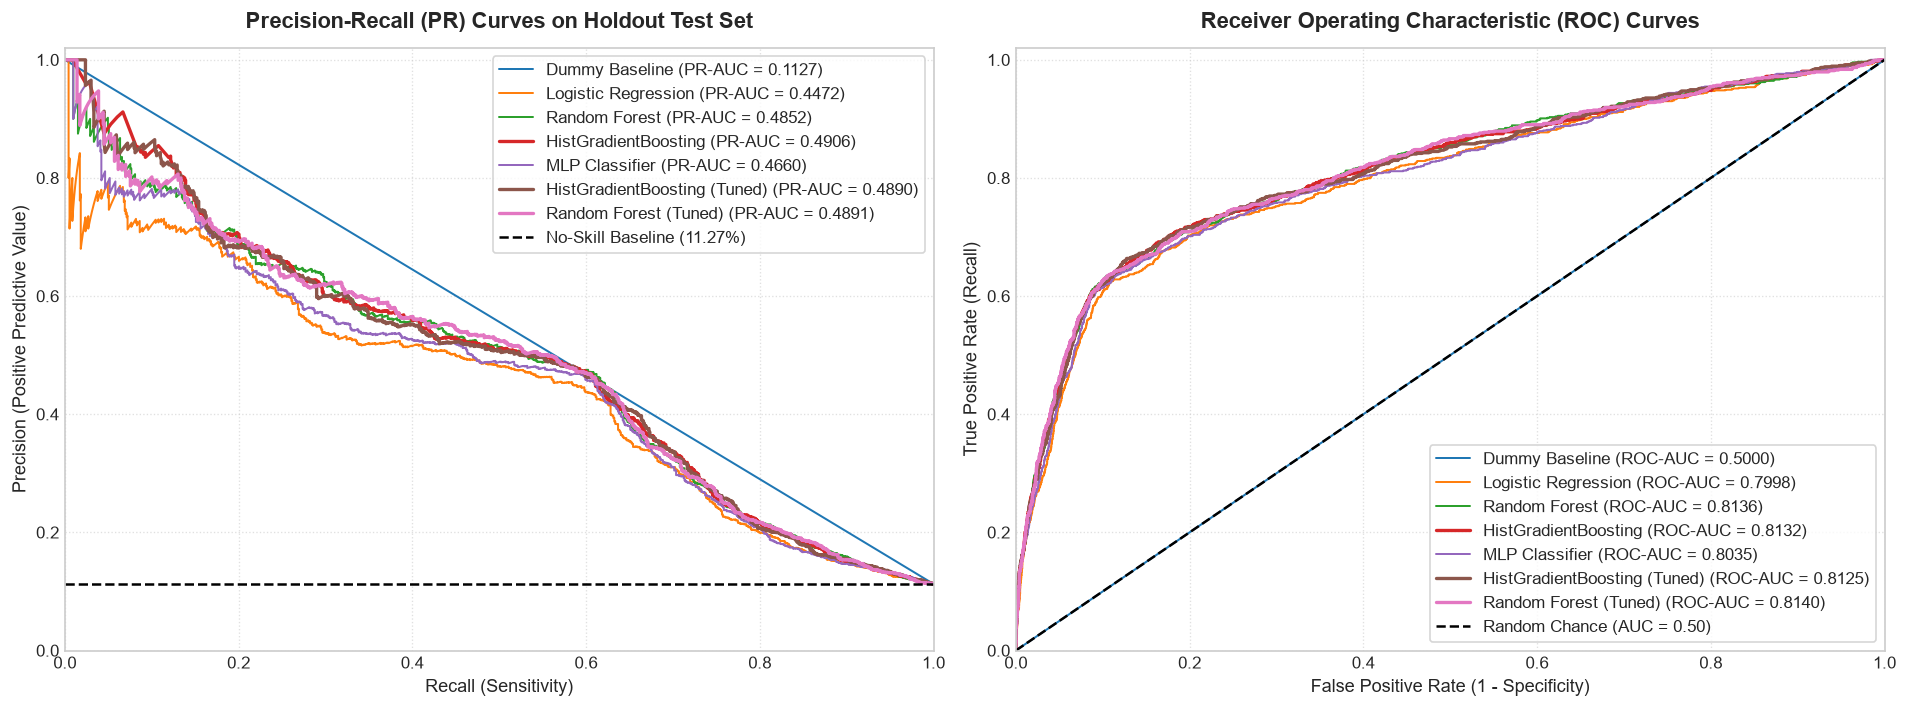

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
palette = sns.color_palette('tab10', n_colors=len(candidate_models))
prevalence = float(y_test.values.mean())

# PR Curves
ax1 = axes[0]
for (name, model), color in zip(candidate_models.items(), palette):
    y_probs = model.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba') else model.predict(X_test)
    prec, rec, _ = precision_recall_curve(y_test.values.ravel(), y_probs)
    score = holdout_results.loc[holdout_results['Model'] == name, 'Holdout PR-AUC'].values[0]
    ax1.plot(rec, prec, label=f"{name} (PR-AUC = {score:.4f})", color=color, linewidth=2 if 'Tuned' in name or name == 'HistGradientBoosting' else 1.2)

ax1.axhline(prevalence, color='black', linestyle='--', linewidth=1.5, label=f'No-Skill Baseline ({prevalence:.2%})')
ax1.set_title('Precision-Recall (PR) Curves on Holdout Test Set', fontsize=13, fontweight='bold', pad=12)
ax1.set_xlabel('Recall (Sensitivity)', fontsize=11)
ax1.set_ylabel('Precision (Positive Predictive Value)', fontsize=11)
ax1.set_xlim([0.0, 1.0])
ax1.set_ylim([0.0, 1.02])
ax1.legend(loc='upper right', frameon=True)
ax1.grid(True, linestyle=':', alpha=0.6)

# ROC Curves
ax2 = axes[1]
for (name, model), color in zip(candidate_models.items(), palette):
    y_probs = model.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba') else model.predict(X_test)
    fpr, tpr, _ = roc_curve(y_test.values.ravel(), y_probs)
    score = holdout_results.loc[holdout_results['Model'] == name, 'Holdout ROC-AUC'].values[0]
    ax2.plot(fpr, tpr, label=f"{name} (ROC-AUC = {score:.4f})", color=color, linewidth=2 if 'Tuned' in name or name == 'HistGradientBoosting' else 1.2)

ax2.plot([0, 1], [0, 1], color='black', linestyle='--', linewidth=1.5, label='Random Chance (AUC = 0.50)')
ax2.set_title('Receiver Operating Characteristic (ROC) Curves', fontsize=13, fontweight='bold', pad=12)
ax2.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
ax2.set_ylabel('True Positive Rate (Recall)', fontsize=11)
ax2.set_xlim([0.0, 1.0])
ax2.set_ylim([0.0, 1.02])
ax2.legend(loc='lower right', frameon=True)
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


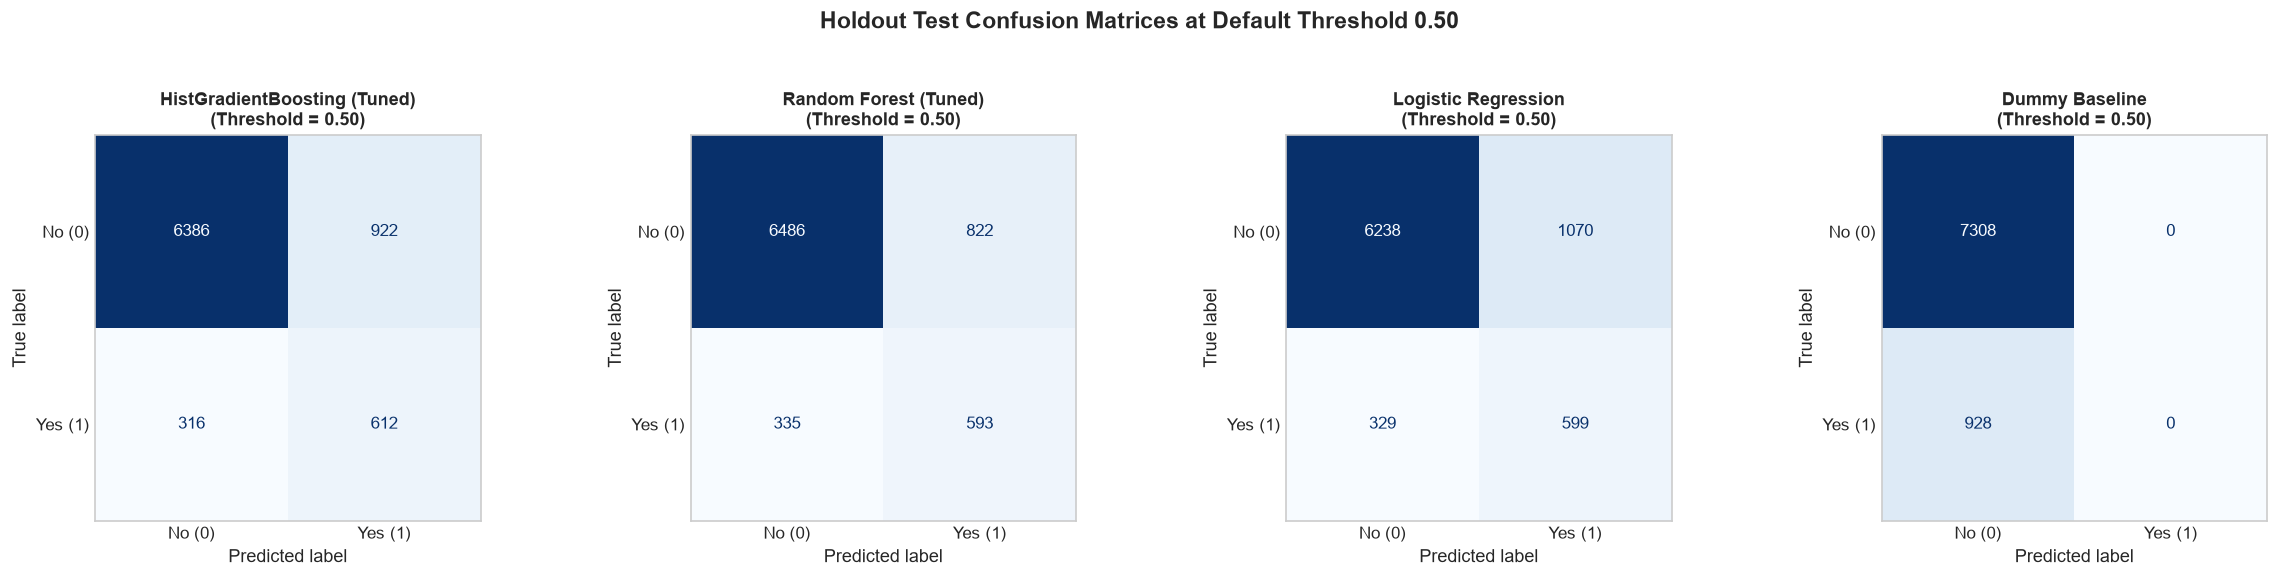

In [27]:
key_models = ['HistGradientBoosting (Tuned)', 'Random Forest (Tuned)', 'Logistic Regression', 'Dummy Baseline']
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))

for ax, name in zip(axes, key_models):
    model = candidate_models[name]
    y_probs = model.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba') else model.predict(X_test)
    y_pred = (y_probs >= 0.50).astype(int)
    cm = confusion_matrix(y_test.values.ravel(), y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No (0)', 'Yes (1)'])
    disp.plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(f"{name}\n(Threshold = 0.50)", fontsize=11, fontweight='bold')
    ax.grid(False)

plt.suptitle('Holdout Test Confusion Matrices at Default Threshold 0.50', fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()


## Section 4: Optimal Threshold Analysis & Operational Trade-offs
We sweep decision thresholds across [0.01, 0.99] for the champion model `HistGradientBoosting (Tuned)` to identify optimal operating points: Max F1 (balanced harvesting), High-Precision (mitigating agent fatigue), and High-Recall (deposit growth).


In [28]:
# 1. Create a reproducible validation split from the training partition.
# The held-out test partition remains untouched until final assessment.
X_train = pd.read_csv("data/processed/X_train_processed.csv")
y_train = pd.read_csv("data/processed/y_train.csv").squeeze("columns")

X_fit, X_validation, y_fit, y_validation = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_train,
)

# Refit the selected estimator on the fit split, then score validation rows.
# Thresholds are selected on these validation predictions only.
validation_model = clone(champion_model)
validation_model.fit(X_fit, y_fit)
validation_predictions = pd.DataFrame({
    "y_true": y_validation.to_numpy(),
    "y_prob": validation_model.predict_proba(X_validation)[:, 1],
})

required_columns = {"y_true", "y_prob"}
if not required_columns.issubset(validation_predictions.columns):
    raise ValueError(
        "Validation CSV must contain y_true and y_prob columns."
    )

# Four decimal places match your current utility's threshold rounding.
# Include exactly 0.50.
thresholds = np.unique(
    np.r_[np.round(np.linspace(0.01, 0.99, 100), 4), 0.50]
)

# 2. Explore thresholds using VALIDATION data only.
threshold_df = compute_threshold_curve(
    validation_predictions["y_true"],
    validation_predictions["y_prob"],
    thresholds=thresholds,
)

# Maximum validation F1.
opt_f1_idx = threshold_df["F1"].idxmax()
opt_f1_row = threshold_df.loc[opt_f1_idx]

# Highest recall among thresholds meeting validation precision >= 50%.
high_prec_candidates = threshold_df[
    threshold_df["Precision"] >= 0.50
]

high_prec_row = (
    high_prec_candidates.sort_values(
        ["Recall", "Precision"], ascending=False
    ).iloc[0]
    if not high_prec_candidates.empty
    else None
)

# Highest precision among thresholds meeting validation recall >= 80%.
high_rec_candidates = threshold_df[
    threshold_df["Recall"] >= 0.80
]

high_rec_row = (
    high_rec_candidates.sort_values(
        ["Precision", "Recall"], ascending=False
    ).iloc[0]
    if not high_rec_candidates.empty
    else None
)

default_row = threshold_df.loc[
    threshold_df["Threshold"] == 0.50
].iloc[0]

# 3. Freeze the validation-selected thresholds.
policies = [
    ("Default Standard", default_row, "Reference cutoff of 0.50"),
    (
        "Max F1",
        opt_f1_row,
        "Highest F1 on the validation threshold grid",
    ),
    (
        "High Precision",
        high_prec_row,
        "Validation precision target >= 50%",
    ),
    (
        "High Recall",
        high_rec_row,
        "Validation recall target >= 80%",
    ),
]

# 4. Predict on the TEST set using the existing selected model.
champion_probs = champion_model.predict_proba(X_test)[:, 1]

# 5. Evaluate the frozen thresholds on TEST data.
# Do not choose new thresholds based on these results.
summary_rows = []

for mode, validation_row, intent in policies:
    if validation_row is None:
        summary_rows.append({
            "Operating Mode": mode,
            "Status": "Target not achieved on validation grid",
            "Operational Intent": intent,
        })
        continue

    threshold = float(validation_row["Threshold"])

    test_row = compute_threshold_curve(
        y_test,
        champion_probs,
        thresholds=np.array([threshold]),
    ).iloc[0]

    summary_rows.append({
        "Operating Mode": mode,
        "Status": "Evaluated",
        "Threshold": threshold,
        "Validation Precision": validation_row["Precision"],
        "Validation Recall": validation_row["Recall"],
        "Validation F1": validation_row["F1"],
        "Test Precision": test_row["Precision"],
        "Test Recall": test_row["Recall"],
        "Test F1": test_row["F1"],
        "Test Balanced Acc": test_row["Balanced Acc"],
        "Test Contact %": (
            f"{test_row['Predicted Positive Rate']:.1%}"
        ),
        "Operational Intent": intent,
    })

tradeoff_summary = pd.DataFrame(summary_rows)

print(f"Selected model: {champion_name}")
print("Thresholds selected on validation data; results assessed on test data.")

display(tradeoff_summary)

Selected model: HistGradientBoosting (Tuned)
Thresholds selected on validation data; results assessed on test data.


,Operating Mode,Status,Threshold,Validation Precision,Validation Recall,Validation F1,Test Precision,Test Recall,Test F1,Test Balanced Acc,Test Contact %,Operational Intent
0,Default Standard,Evaluated,0.5000,0.3850,0.6429,0.4816,0.3990,0.6595,0.4972,0.7667,18.6%,Reference cutoff of 0.50
1,Max F1,Evaluated,0.5841,0.4385,0.6011,0.5071,0.4484,0.6175,0.5195,0.7605,15.5%,Highest F1 on the validation threshold grid
2,High Precision,Evaluated,0.7722,0.5105,0.4582,0.4830,0.5102,0.4849,0.4972,0.7129,10.7%,Validation precision target >= 50%
3,High Recall,Evaluated,0.3565,0.2389,0.8005,0.3680,0.2314,0.7759,0.3564,0.7243,37.8%,Validation recall target >= 80%


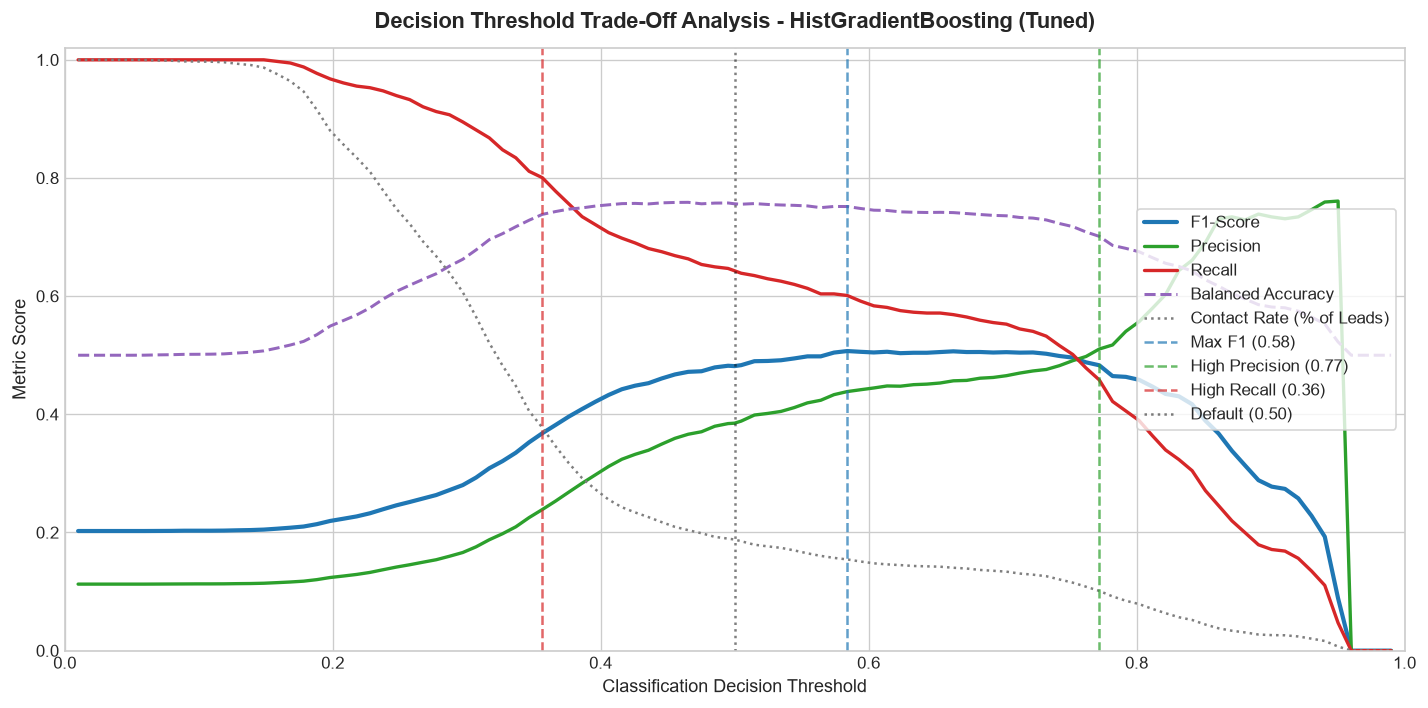

In [29]:
plt.figure(figsize=(12, 6))
plt.plot(threshold_df['Threshold'], threshold_df['F1'], label='F1-Score', color='#1f77b4', linewidth=2.5)
plt.plot(threshold_df['Threshold'], threshold_df['Precision'], label='Precision', color='#2ca02c', linewidth=2)
plt.plot(threshold_df['Threshold'], threshold_df['Recall'], label='Recall', color='#d62728', linewidth=2)
plt.plot(threshold_df['Threshold'], threshold_df['Balanced Acc'], label='Balanced Accuracy', color='#9467bd', linestyle='--', linewidth=1.8)
plt.plot(threshold_df['Threshold'], threshold_df['Predicted Positive Rate'], label='Contact Rate (% of Leads)', color='#7f7f7f', linestyle=':', linewidth=1.5)

plt.axvline(opt_f1_row['Threshold'], color='#1f77b4', linestyle='--', alpha=0.7, label=f"Max F1 ({opt_f1_row['Threshold']:.2f})")
plt.axvline(high_prec_row['Threshold'], color='#2ca02c', linestyle='--', alpha=0.7, label=f"High Precision ({high_prec_row['Threshold']:.2f})")
plt.axvline(high_rec_row['Threshold'], color='#d62728', linestyle='--', alpha=0.7, label=f"High Recall ({high_rec_row['Threshold']:.2f})")
plt.axvline(0.50, color='black', linestyle=':', alpha=0.5, label='Default (0.50)')

plt.title(f'Decision Threshold Trade-Off Analysis - {champion_name}', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Classification Decision Threshold', fontsize=11)
plt.ylabel('Metric Score', fontsize=11)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.02])
plt.legend(loc='center right', frameon=True, bbox_to_anchor=(1.0, 0.55))
plt.tight_layout()
plt.show()


## Section 5: Probability Calibration & Reliability Diagrams
We evaluate probability trustworthiness by generating reliability diagrams across 10 probability bins and quantifying Expected Calibration Error (ECE) and Brier Score.


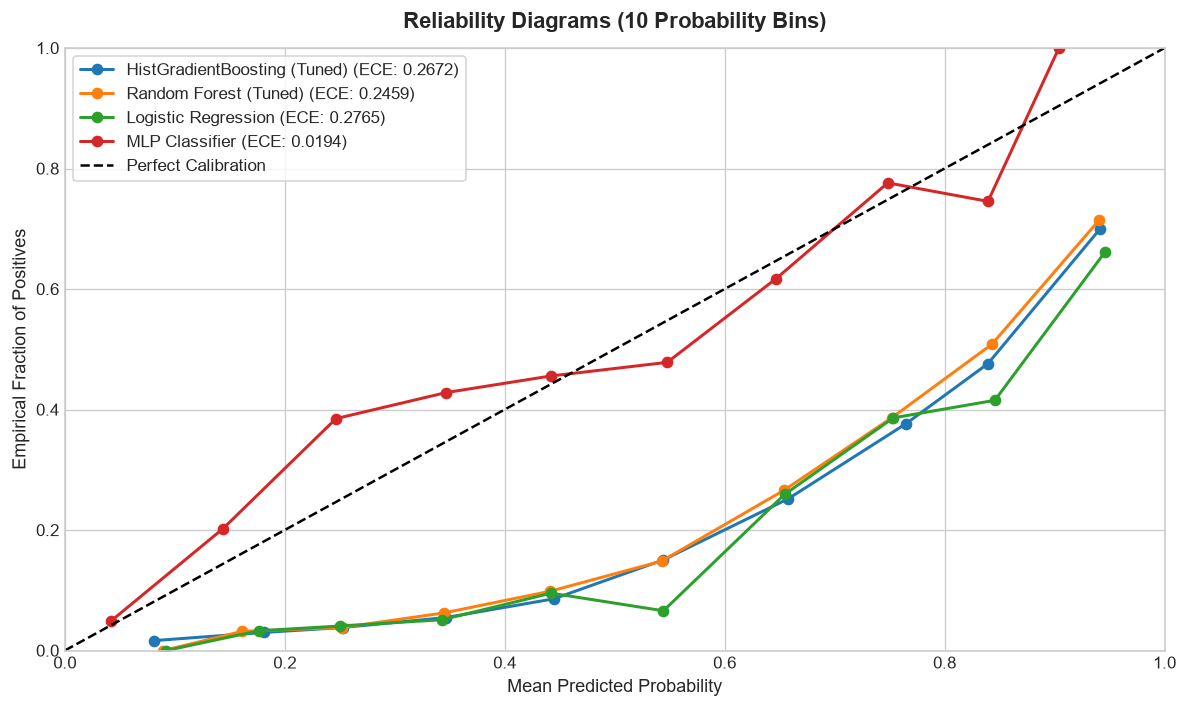

,Model,Brier Score Loss,Expected Calibration Error (ECE)
3,MLP Classifier,0.0778,0.0194
1,Random Forest (Tuned),0.1421,0.2459
0,HistGradientBoosting (Tuned),0.1529,0.2672
2,Logistic Regression,0.1618,0.2765


In [30]:
calib_models = {
    'HistGradientBoosting (Tuned)': champion_probs,
    'Random Forest (Tuned)': candidate_models['Random Forest (Tuned)'].predict_proba(X_test)[:, 1],
    'Logistic Regression': candidate_models['Logistic Regression'].predict_proba(X_test)[:, 1],
    'MLP Classifier': candidate_models['MLP Classifier'].predict_proba(X_test)[:, 1]
}

calib_summary_records = []
fig, ax = plt.subplots(figsize=(10, 6))

for name, probs in calib_models.items():
    calib_metrics = compute_calibration_metrics(y_test, probs, n_bins=10)
    calib_summary_records.append({
        'Model': name,
        'Brier Score Loss': calib_metrics['brier_score'],
        'Expected Calibration Error (ECE)': calib_metrics['ece']
    })
    ax.plot(calib_metrics['prob_pred'], calib_metrics['prob_true'], marker='o', linewidth=1.8, label=f"{name} (ECE: {calib_metrics['ece']:.4f})")

ax.plot([0, 1], [0, 1], linestyle='--', color='black', linewidth=1.5, label='Perfect Calibration')
ax.set_title('Reliability Diagrams (10 Probability Bins)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Mean Predicted Probability', fontsize=11)
ax.set_ylabel('Empirical Fraction of Positives', fontsize=11)
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
ax.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

pd.DataFrame(calib_summary_records).sort_values(by='Expected Calibration Error (ECE)')


## Section 6: Business Translation - Lift, Cumulative Gains & Contact Budgets
We construct Cumulative Gains and Lift Curves across 10 deciles and formulate an operational tele-calling capacity budget table.


In [31]:
lift_table = calculate_lift_and_gain(y_test, champion_probs, bins=10)
lift_table


,Decile,Leads,Cum Leads,Cum Contact %,Responders,Cum Responders,Cum Capture %,Hit Rate,Lift
0,1,824,824,10.00,428,428,46.12,0.5194,4.61
1,2,824,1648,20.01,193,621,66.92,0.2342,3.34
2,3,823,2471,30.00,66,687,74.03,0.0802,2.47
3,4,824,3295,40.01,44,731,78.77,0.0534,1.97
4,5,823,4118,50.00,49,780,84.05,0.0595,1.68
5,6,824,4942,60.00,24,804,86.64,0.0291,1.44
6,7,823,5765,70.00,44,848,91.38,0.0535,1.31
7,8,824,6589,80.00,33,881,94.94,0.0400,1.19
8,9,823,7412,90.00,22,903,97.31,0.0267,1.08
9,10,824,8236,100.00,25,928,100.00,0.0303,1.00


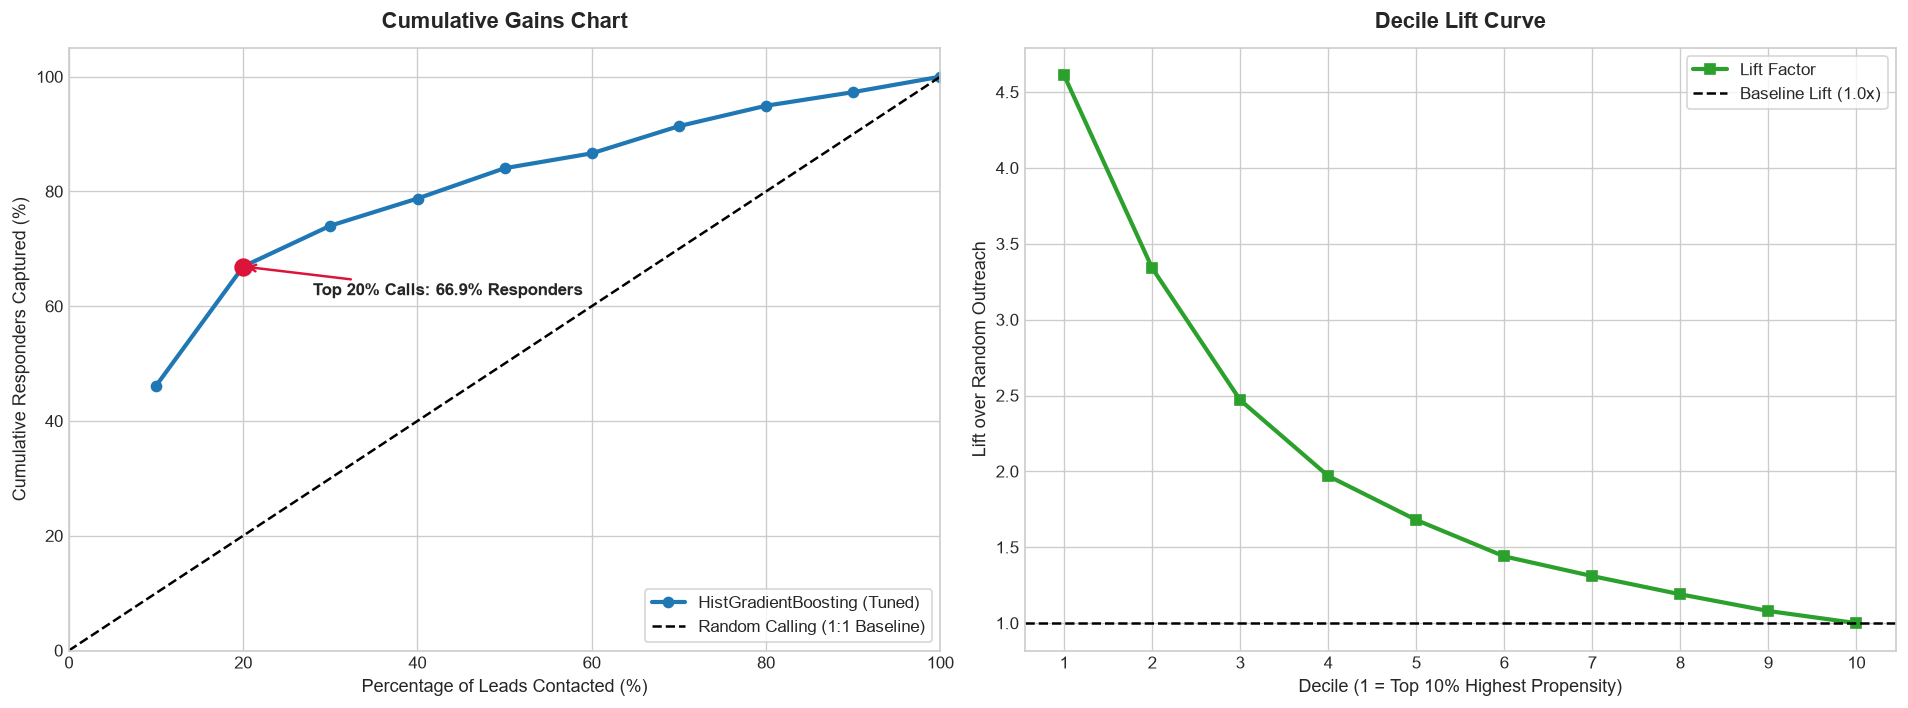

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax1 = axes[0]
ax1.plot(lift_table['Cum Contact %'], lift_table['Cum Capture %'], marker='o', color='#1f77b4', linewidth=2.5, label=f"{champion_name}")
ax1.plot([0, 100], [0, 100], linestyle='--', color='black', linewidth=1.5, label='Random Calling (1:1 Baseline)')

cap_20 = lift_table.loc[lift_table['Decile'] == 2, 'Cum Capture %'].values[0]
ax1.scatter([20.0], [cap_20], color='crimson', s=100, zorder=5)
ax1.annotate(f"Top 20% Calls: {cap_20:.1f}% Responders",
             xy=(20.0, cap_20), xytext=(28, cap_20 - 5),
             arrowprops=dict(arrowstyle='->', lw=1.5, color='crimson'),
             fontweight='bold', fontsize=10)

ax1.set_title('Cumulative Gains Chart', fontsize=13, fontweight='bold', pad=12)
ax1.set_xlabel('Percentage of Leads Contacted (%)', fontsize=11)
ax1.set_ylabel('Cumulative Responders Captured (%)', fontsize=11)
ax1.set_xlim([0, 100])
ax1.set_ylim([0, 105])
ax1.legend(loc='lower right', frameon=True)

ax2 = axes[1]
ax2.plot(lift_table['Decile'], lift_table['Lift'], marker='s', color='#2ca02c', linewidth=2.5, label='Lift Factor')
ax2.axhline(1.0, linestyle='--', color='black', linewidth=1.5, label='Baseline Lift (1.0x)')
ax2.set_title('Decile Lift Curve', fontsize=13, fontweight='bold', pad=12)
ax2.set_xlabel('Decile (1 = Top 10% Highest Propensity)', fontsize=11)
ax2.set_ylabel('Lift over Random Outreach', fontsize=11)
ax2.set_xticks(range(1, 11))
ax2.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()


In [33]:
capacity_budget = lift_table[lift_table['Decile'].isin([1, 2, 3, 4, 5])].copy()
capacity_budget['Tele-Marketing Staffing Scenario'] = [
    'Highly Constrained Outreach (Top 10%)',
    'Standard Efficient Outreach (Top 20%)',
    'Growth Campaign Outreach (Top 30%)',
    'Aggressive Outreach (Top 40%)',
    'Broad Market Sweep (Top 50%)'
]
capacity_budget[['Tele-Marketing Staffing Scenario', 'Cum Leads', 'Cum Contact %', 'Cum Responders', 'Cum Capture %', 'Hit Rate', 'Lift']]


,Tele-Marketing Staffing Scenario,Cum Leads,Cum Contact %,Cum Responders,Cum Capture %,Hit Rate,Lift
0,Highly Constrained Outreach (Top 10%),824,10.00,428,46.12,0.5194,4.61
1,Standard Efficient Outreach (Top 20%),1648,20.01,621,66.92,0.2342,3.34
2,Growth Campaign Outreach (Top 30%),2471,30.00,687,74.03,0.0802,2.47
3,Aggressive Outreach (Top 40%),3295,40.01,731,78.77,0.0534,1.97
4,Broad Market Sweep (Top 50%),4118,50.00,780,84.05,0.0595,1.68


## Section 7: In-Depth Error & Failure Analysis
We isolate and inspect False Positives and False Negatives at the optimal operating threshold to understand failure drivers.


In [34]:
df_errors = X_test.copy()
df_errors['y_true'] = y_test.values.ravel()
df_errors['y_prob'] = champion_probs
df_errors['y_pred'] = (champion_probs >= opt_f1_row['Threshold']).astype(int)

def assign_outcome(row):
    if row['y_true'] == 1 and row['y_pred'] == 1:
        return 'True Positive (TP)'
    elif row['y_true'] == 0 and row['y_pred'] == 0:
        return 'True Negative (TN)'
    elif row['y_true'] == 0 and row['y_pred'] == 1:
        return 'False Positive (FP)'
    else:
        return 'False Negative (FN)'

df_errors['Outcome'] = df_errors.apply(assign_outcome, axis=1)
outcome_counts = df_errors['Outcome'].value_counts()
print("Error Breakdown at Balanced Harvesting Threshold:")
for k, v in outcome_counts.items():
    print(f"  {k:22s}: {v:,} ({v / len(df_errors):.2%})")


Error Breakdown at Balanced Harvesting Threshold:
  True Negative (TN)    : 6,603 (80.17%)
  False Positive (FP)   : 705 (8.56%)
  True Positive (TP)    : 573 (6.96%)
  False Negative (FN)   : 355 (4.31%)


## Section 8: Subgroup Performance & Algorithmic Fairness
We assess demographic equity and error rates across age cohorts and job types using aligned raw metadata.


In [35]:
from sklearn.model_selection import train_test_split

df_raw = pd.read_csv('data/raw/bank-additional-full.csv', sep=';').drop_duplicates()
y_raw = df_raw['y'].map({'no': 0, 'yes': 1}).astype(int)
X_raw = df_raw.drop(columns=['y', 'duration'])

_, X_meta_test, _, _ = train_test_split(X_raw, y_raw, test_size=0.20, random_state=RANDOM_STATE, stratify=y_raw)
X_meta_test = X_meta_test.reset_index(drop=True)

X_meta_test['age_group'] = pd.cut(
    X_meta_test['age'],
    bins=[0, 30, 60, 120],
    labels=['Young Adults (<=30)', 'Middle-Aged (31-60)', 'Seniors (>60)']
)

age_fairness = evaluate_subgroup_performance(
    y_true=y_test,
    y_probs=champion_probs,
    metadata_df=X_meta_test,
    attribute_col='age_group',
    threshold=opt_f1_row['Threshold']
)
print("=== Age Cohort Subgroup Performance ===")
age_fairness


=== Age Cohort Subgroup Performance ===


,Subgroup,Sample Count,Prevalence,Pred Positives,FPR,FNR,Precision,Recall
0,Middle-Aged (31-60),6635,0.0956,745,0.0673,0.4621,0.4577,0.5379
1,Young Adults (<=30),1434,0.1499,368,0.1756,0.2837,0.4185,0.7163
2,Seniors (>60),167,0.4731,165,0.9886,0.0127,0.4727,0.9873


In [36]:
job_fairness = evaluate_subgroup_performance(
    y_true=y_test,
    y_probs=champion_probs,
    metadata_df=X_meta_test,
    attribute_col='job',
    threshold=opt_f1_row['Threshold']
)
print("=== Job Category Subgroup Performance (Top Categories) ===")
job_fairness.head(8)


=== Job Category Subgroup Performance (Top Categories) ===


,Subgroup,Sample Count,Prevalence,Pred Positives,FPR,FNR,Precision,Recall
0,admin.,2150,0.1316,441,0.1285,0.2898,0.4558,0.7102
1,blue-collar,1813,0.0673,73,0.0237,0.7295,0.4521,0.2705
2,technician,1319,0.1122,181,0.0828,0.4324,0.4641,0.5676
3,services,786,0.0814,58,0.0457,0.6094,0.4310,0.3906
4,management,584,0.1096,89,0.0942,0.3750,0.4494,0.6250
5,retired,330,0.2303,151,0.3307,0.1184,0.4437,0.8816
6,self-employed,307,0.1107,59,0.1392,0.3824,0.3559,0.6176
7,entrepreneur,297,0.0808,25,0.0549,0.5833,0.4000,0.4167


## Section 9: Diagnostic Experiment - The Leakage Hazard of `duration`
We train a diagnostic model that intentionally includes post-contact call duration to empirically demonstrate artificial metric inflation and explain why post-contact variables must never be deployed for pre-contact lead scoring.


In [37]:
df_raw_with_dur = pd.read_csv('data/raw/bank-additional-full.csv', sep=';').drop_duplicates()
y_dur = df_raw_with_dur['y'].map({'no': 0, 'yes': 1}).astype(int)
X_dur = df_raw_with_dur.drop(columns=['y'])

X_dur_tr, X_dur_te, y_dur_tr, y_dur_te = train_test_split(
    X_dur, y_dur, test_size=0.20, random_state=RANDOM_STATE, stratify=y_dur
)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import average_precision_score, roc_auc_score

num_cols = X_dur.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X_dur.select_dtypes(include=['object']).columns.tolist()

diag_preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)

leaked_pipeline = Pipeline([
    ('prep', diag_preprocessor),
    ('clf', HistGradientBoostingClassifier(random_state=RANDOM_STATE))
])

leaked_pipeline.fit(X_dur_tr, y_dur_tr)
leaked_probs = leaked_pipeline.predict_proba(X_dur_te)[:, 1]

leaked_pr_auc = average_precision_score(y_dur_te, leaked_probs)
leaked_roc_auc = roc_auc_score(y_dur_te, leaked_probs)

real_pr_auc = holdout_results.loc[holdout_results['Model'] == 'HistGradientBoosting', 'Holdout PR-AUC'].values[0]
real_roc_auc = holdout_results.loc[holdout_results['Model'] == 'HistGradientBoosting', 'Holdout ROC-AUC'].values[0]

leakage_comparison = pd.DataFrame([
    {
        'Framework Setting': 'Realistic Pre-Contact Pipeline (Production Ready)',
        'Duration Variable Status': 'EXCLUDED (Zero Leakage)',
        'PR-AUC': round(real_pr_auc, 4),
        'ROC-AUC': round(real_roc_auc, 4),
        'Feasibility for Outbound Prioritization': 'VALID (Known before dialing)'
    },
    {
        'Framework Setting': 'Flawed Post-Contact Pipeline (Leaked Diagnostic)',
        'Duration Variable Status': 'INCLUDED (Target Leakage)',
        'PR-AUC': round(leaked_pr_auc, 4),
        'ROC-AUC': round(leaked_roc_auc, 4),
        'Feasibility for Outbound Prioritization': 'FATAL (Unknown before dialing)'
    }
])
leakage_comparison


C:\Users\sande\AppData\Local\Temp\ipykernel_39768\4002434450.py:15: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_dur.select_dtypes(include=['object']).columns.tolist()


,Framework Setting,Duration Variable Status,PR-AUC,ROC-AUC,Feasibility for Outbound Prioritization
0,Realistic Pre-Contact Pipeline (Production Ready),EXCLUDED (Zero Leakage),0.4906,0.8132,VALID (Known before dialing)
1,Flawed Post-Contact Pipeline (Leaked Diagnostic),INCLUDED (Target Leakage),0.6735,0.9512,FATAL (Unknown before dialing)


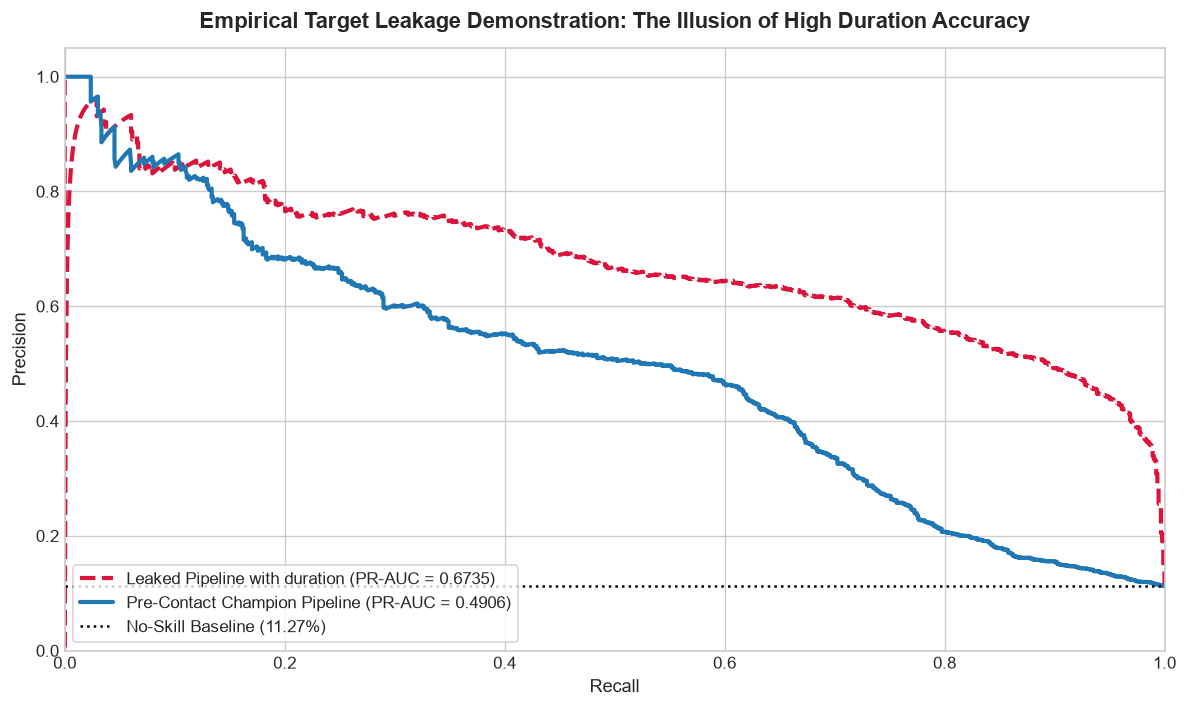

In [38]:
prec_leak, rec_leak, _ = precision_recall_curve(y_dur_te, leaked_probs)
prec_real, rec_real, _ = precision_recall_curve(y_test.values.ravel(), champion_probs)

plt.figure(figsize=(10, 6))
plt.plot(rec_leak, prec_leak, label=f'Leaked Pipeline with duration (PR-AUC = {leaked_pr_auc:.4f})', color='crimson', linewidth=2.5, linestyle='--')
plt.plot(rec_real, prec_real, label=f'Pre-Contact Champion Pipeline (PR-AUC = {real_pr_auc:.4f})', color='#1f77b4', linewidth=2.5)
plt.axhline(prevalence, color='black', linestyle=':', label=f'No-Skill Baseline ({prevalence:.2%})')

plt.title('Empirical Target Leakage Demonstration: The Illusion of High Duration Accuracy', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Recall', fontsize=11)
plt.ylabel('Precision', fontsize=11)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.legend(loc='lower left', frameon=True)
plt.tight_layout()
plt.show()


### Final Conclusion on `duration` Target Leakage
The diagnostic comparison shows higher holdout scores when duration is included (PR-AUC 0.6735, ROC-AUC 0.9512) than for the pre-contact model (PR-AUC 0.4906, ROC-AUC 0.8132).
Because call duration is only known after a conversation, those scores cannot be used for pre-dial lead prioritization. This comparison illustrates the risk of post-contact leakage; the score difference should not be attributed to duration alone because the models use different configurations. 
The pre-contact model therefore excludes duration and relies on features available before dialing.